In [1]:
import csv

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Path Specifications

In [2]:
dataset = "model/data/keypoint_final.csv"
model_save_path = 'model/training/keypoint_classifier_final.keras'
tflite_save_path = 'model/training/keypoint_classifier_final.tflite'

# Number of classes

In [3]:
import utils.file_helper as fh
labels = fh.load_labels()

NUM_CLASSES = len(labels)
print(f"Number of classes: {NUM_CLASSES}")

Number of classes: 5


# Read dataset and split intro train/test

In [4]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32', usecols=list(range(1, (21 * 2) + 1)))
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0))
X_train, X_test, y_train, y_test = train_test_split(X_dataset, y_dataset, train_size=0.75, stratify = y_dataset, random_state=RANDOM_SEED)

# Model Build (Neural Network)

In [5]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input((21 * 2, )),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dropout (Dropout)                    │ (None, 42)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 20)                  │             860 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 20)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             210 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │              55 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,125 (4.39 KB)

 Trainable params: 1,125 (4.39 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Model callback save in case the training fails at some point
cp_callback = tf.keras.callbacks.ModelCheckpoint(model_save_path, verbose=1, save_weights_only=False)
# Early stop if the model doesn't see relevant improvements for a number of epochs
es_callback = tf.keras.callbacks.EarlyStopping(patience=20, verbose=1)

In [7]:
# Model compilation
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Model Train

In [8]:
model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

Epoch 1/1000
1/4 ━━━━━━━━━━━━━━━━━━━━ 2s 671ms/step - accuracy: 0.0469 - loss: 2.1447
Epoch 1: saving model to model/training/keypoint_classifier_final.keras

Epoch 1: finished saving model to model/training/keypoint_classifier_final.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.0835 - loss: 2.0732 - val_accuracy: 0.1346 - val_loss: 1.9277
Epoch 2/1000
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.0391 - loss: 2.0529
Epoch 2: saving model to model/training/keypoint_classifier_final.keras

Epoch 2: finished saving model to model/training/keypoint_classifier_final.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1028 - loss: 1.9985 - val_accuracy: 0.1731 - val_loss: 1.8491
Epoch 3/1000
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1797 - loss: 1.9714
Epoch 3: saving model to model/training/keypoint_classifier_final.keras

Epoch 3: finished saving model to model/training/keypoint_classifier_final.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.16

In [9]:
# Model evaluation
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9615 - loss: 0.2273


In [10]:
# Loading the saved model
model = tf.keras.models.load_model(model_save_path)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


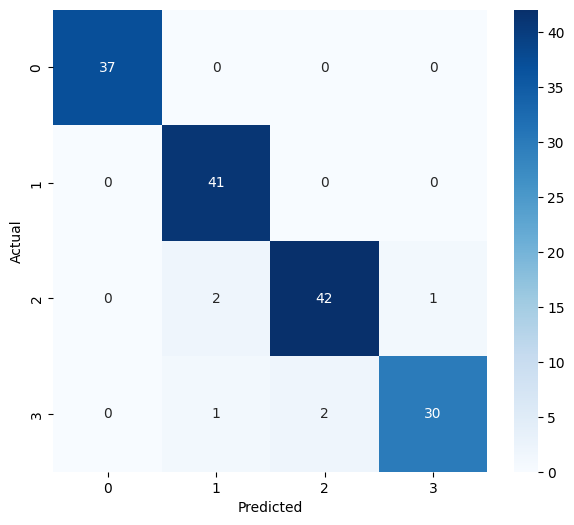

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        37
           1       0.93      1.00      0.96        41
           2       0.95      0.93      0.94        45
           3       0.97      0.91      0.94        33

    accuracy                           0.96       156
   macro avg       0.96      0.96      0.96       156
weighted avg       0.96      0.96      0.96       156



In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def plot_confusion_matrix(y_true, y_pred, report=True):
    
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()
    
    if report:
        print('Classification Report')
        print(classification_report(y_test, y_pred))

Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)
plot_confusion_matrix(y_test, y_pred)

# Converting the model to Tensorflow-Lite

In [12]:
# Saving as a model dedicated to inference (removing the optimizer)
model.save(model_save_path, include_optimizer=False)

In [13]:
# Converting model + quantization

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

open(tflite_save_path, 'wb').write(tflite_quantized_model)

INFO:tensorflow:Assets written to: C:\Users\andre\AppData\Local\Temp\tmp280lx9pn\assets


INFO:tensorflow:Assets written to: C:\Users\andre\AppData\Local\Temp\tmp280lx9pn\assets


Saved artifact at 'C:\Users\andre\AppData\Local\Temp\tmp280lx9pn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 42), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  2664253408848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2664253409040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2664253409616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2664253410192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2664253409424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2664253415568: TensorSpec(shape=(), dtype=tf.resource, name=None)


6688